# Ex 1.

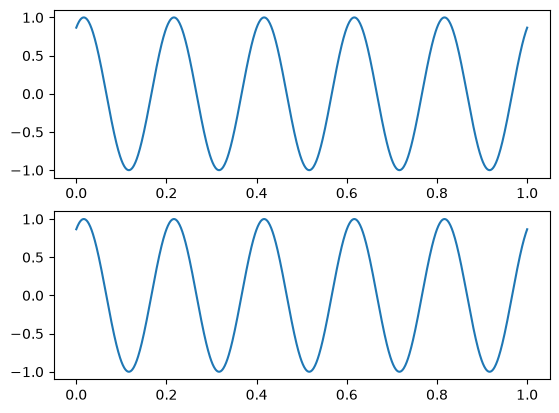

In [10]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 1, 1000)

x = np.sin(2 * np.pi * 5 * t + np.pi / 3)
y = np.cos(2 * np.pi * 5 * t + np.pi / 3 - np.pi / 2)

fig, axs = plt.subplots(2)
axs[0].plot(t, x)
axs[1].plot(t, y)

# Ex 2.

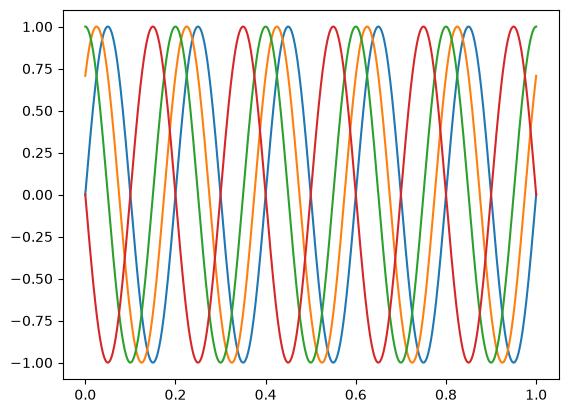

In [11]:
t = np.linspace(0, 1, 1000)

plt.figure()
for phi in [0, np.pi / 4, np.pi / 2, np.pi]:
    plt.plot(t, np.sin(2 * np.pi * 5 * t + phi))

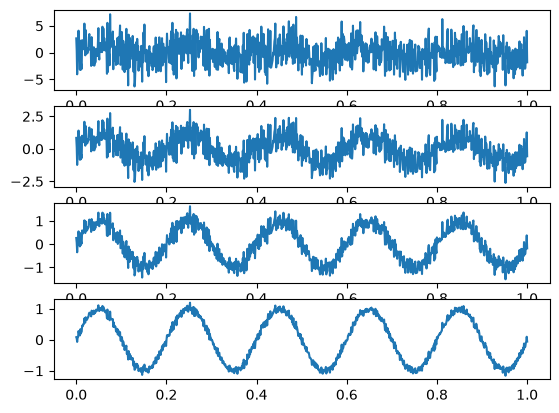

In [12]:
x = np.sin(2 * np.pi * 5 * t)
z = np.random.normal(size=len(t))

fig, axs = plt.subplots(4)
for i, snr in enumerate([0.1, 1, 10, 100]):
    gamma = np.sqrt(np.linalg.norm(x) ** 2 / (snr * np.linalg.norm(z) ** 2))
    axs[i].plot(t, x + gamma * z)

# Ex 3

In [13]:
import sounddevice as sd
import scipy.io.wavfile

sample_rate = 44100
t = np.linspace(0, 1, sample_rate)

signals = [
    np.sin(2 * np.pi * 400 * t),
    np.sin(2 * np.pi * 800 * t),
    np.mod(240 * t, 1),
    np.sign(np.sin(2 * np.pi * 300 * t)),
]

for x in signals:
    sd.play(x, sample_rate)
    sd.wait()

In [14]:
scipy.io.wavfile.write('sawtooth.wav', sample_rate, signals[2])
rate, x = scipy.io.wavfile.read('sawtooth.wav')
print(rate, np.allclose(x, signals[2]))

44100 True


# Ex 4

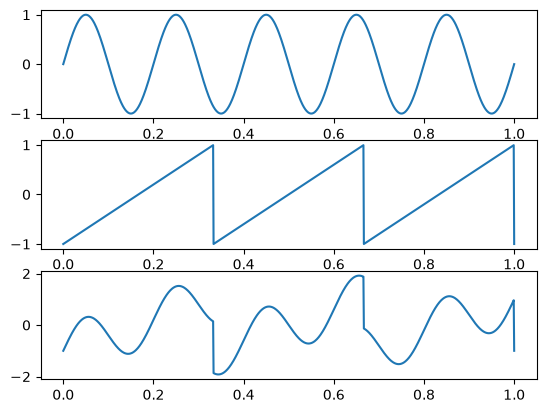

In [15]:
import scipy.signal

t = np.linspace(0, 1, 1000)

x = np.sin(2 * np.pi * 5 * t)
y = scipy.signal.sawtooth(2 * np.pi * 3 * t)

fig, axs = plt.subplots(3)
axs[0].plot(t, x)
axs[1].plot(t, y)
axs[2].plot(t, x + y)

# Ex 5

In [16]:
t = np.linspace(0, 1, sample_rate)

x = np.sin(2 * np.pi * 440 * t)
# cvinta perfecta
y = np.sin(2 * np.pi * 440 * 4 / 3 * t)

sd.play(np.concatenate([x, y]), sample_rate)
sd.wait()

# Ex 6

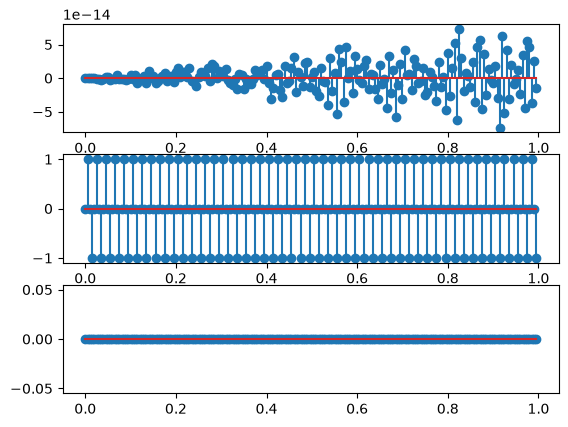

In [17]:
sample_rate = 200
t = np.arange(sample_rate) / sample_rate

fig, axs = plt.subplots(3)
for i, f in enumerate([sample_rate / 2, sample_rate / 4, 0]):
    axs[i].stem(t, np.sin(2 * np.pi * f * t))

# Ex 7

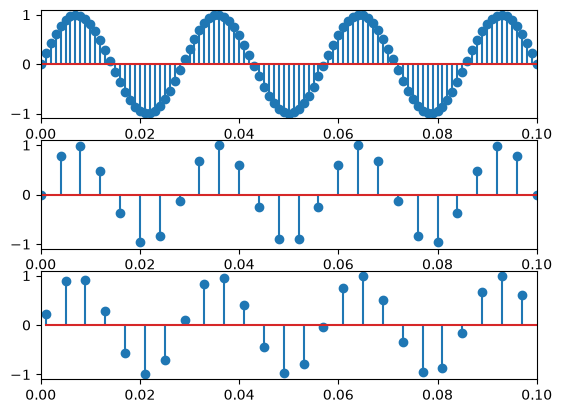

In [18]:
sample_rate = 1000
t = np.arange(sample_rate) / sample_rate
x = np.sin(2 * np.pi * 35 * t)

fig, axs = plt.subplots(3)
axs[0].stem(t, x)
axs[1].stem(t[::4], x[::4])
axs[2].stem(t[1::4], x[1::4])

for ax in axs.flat:
    ax.set_xlim([0, 0.1])

# Ex 8

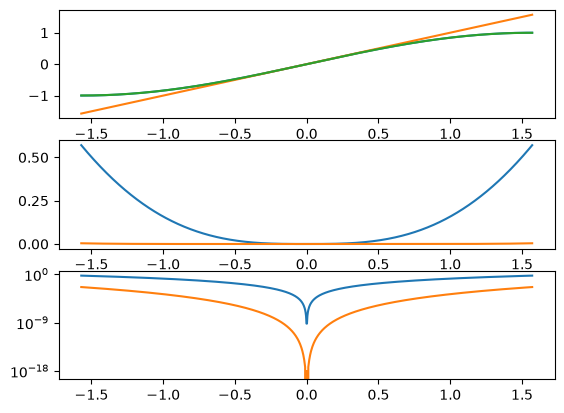

In [19]:
a = np.linspace(-np.pi / 2, np.pi / 2, 1000)
s = np.sin(a)
pade = (a - 7 * a ** 3 / 60) / (1 + a ** 2 / 20)

fig, axs = plt.subplots(3)
axs[0].plot(a, s)
axs[0].plot(a, a)
axs[0].plot(a, pade)

axs[1].plot(a, np.abs(s - a))
axs[1].plot(a, np.abs(s - pade))

axs[2].plot(a, np.abs(s - a))
axs[2].plot(a, np.abs(s - pade))
axs[2].set_yscale('log')